## 1. Chargement des données

On charge le fichier CSV et on vérifie rapidement les colonnes et les premières lignes. Cela permet de confirmer le schéma des données avant toute modélisation.

In [1]:
from pathlib import Path
import pandas as pd

path = Path("bank_transactions.csv")
df = pd.read_csv(path)
print(f"Forme du dataset : {df.shape}")
print(df.head())
print("\nColonnes :", list(df.columns))


Forme du dataset : (5000, 9)
  transaction_id account_id  amount  hour country merchant_category  \
0       TX000001    ACC0090  383.72     4      FR         ECOMMERCE   
1       TX000002    ACC0774  516.48     0      BE         ECOMMERCE   
2       TX000003    ACC0655  151.95    15      DE           GROCERY   
3       TX000004    ACC0439   34.56    16      FR           GROCERY   
4       TX000005    ACC0434   93.14    18      FR         TRANSPORT   

   transactions_last_24h  average_amount_last_7d  is_fraud  
0                      6                  217.44         0  
1                      1                  275.06         0  
2                      1                  100.82         0  
3                      4                   33.88         0  
4                      0                  276.66         0  

Colonnes : ['transaction_id', 'account_id', 'amount', 'hour', 'country', 'merchant_category', 'transactions_last_24h', 'average_amount_last_7d', 'is_fraud']


## 2. Proportion des fraudes et valeurs manquantes

Nous mesurons d'abord la rareté de la fraude et la qualité des colonnes, car les jeux de données de fraude sont généralement très déséquilibrés.

In [2]:
fraud_rate = df["is_fraud"].mean()
missing = df.isna().sum().sort_values(ascending=False)
print(f"Proportion de fraudes : {fraud_rate:.2%}")
print("\nValeurs manquantes par colonne :")
print(missing[missing > 0].to_string())
if (missing == 0).all():
    print("\nAucune valeur manquante détectée.")


Proportion de fraudes : 5.14%

Valeurs manquantes par colonne :
merchant_category         84
average_amount_last_7d    75
country                   66


## 3. Séparation train/test stratifiée avant tout prétraitement

Le découpage est fait avant le prétraitement pour éviter toute fuite d'information provenant du jeu de test et pour préserver la proportion de fraude dans chaque sous-ensemble.

In [3]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["is_fraud"])
y = df["is_fraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Train shape : {X_train.shape}")
print(f"Test shape : {X_test.shape}")
print(f"Fraude train : {y_train.mean():.2%}")
print(f"Fraude test : {y_test.mean():.2%}")


Train shape : (4000, 8)
Test shape : (1000, 8)
Fraude train : 5.15%
Fraude test : 5.10%


## 4. Suppression des identifiants non utiles

Les identifiants de transaction et de compte ne sont pas des variables explicatives pertinentes pour détecter la fraude ; on les retire avant la construction des features.

In [4]:
drop_cols = ["transaction_id", "account_id"]
X_train = X_train.drop(columns=drop_cols)
X_test = X_test.drop(columns=drop_cols)
print(X_train.head())
print("\nColonnes finales :", list(X_train.columns))


      amount  hour country merchant_category  transactions_last_24h  \
1429   52.42     3      FR       ELECTRONICS                      5   
1032   29.31    18      FR            TRAVEL                      1   
3915   34.34    14      FR         ECOMMERCE                      6   
4577   81.66     3      BE           GROCERY                      5   
2413   40.11     7      FR            TRAVEL                      6   

      average_amount_last_7d  
1429                  109.21  
1032                   46.52  
3915                   45.59  
4577                   83.05  
2413                   78.72  

Colonnes finales : ['amount', 'hour', 'country', 'merchant_category', 'transactions_last_24h', 'average_amount_last_7d']


## 5. Pipeline de prétraitement scikit-learn

Le pipeline applique un prétraitement adapté à chaque type de variable : médiane + standardisation pour les numériques, mode + one-hot encoding pour les catégorielles, en ajustant uniquement sur le train.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_cols = X_train.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=["number"]).columns.tolist()

num_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", num_transformer, num_cols),
        ("categorical", cat_transformer, cat_cols),
    ]
)

base_model = LogisticRegression(class_weight="balanced", max_iter=1000)
model_pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("model", base_model)])
model_pipeline.fit(X_train, y_train)

X_train_processed = model_pipeline.named_steps["preprocessor"].transform(X_train)
print(f"Forme après prétraitement du train : {X_train_processed.shape}")
print(f"Nombre de variables transformées : {X_train_processed.shape[1]}")


Forme après prétraitement du train : (4000, 15)
Nombre de variables transformées : 15


## 6. Modèle et comparaison sur le train en validation croisée

On compare rapidement un modèle linéaire et un arbre aléatoire sur le train avec validation croisée stratifiée et score average_precision, puis on garde le meilleur modèle.

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {
    "LogisticRegression": LogisticRegression(class_weight="balanced", max_iter=1000),
    "RandomForest": RandomForestClassifier(class_weight="balanced", random_state=42)
}

results = {}
for name, model in models.items():
    clf = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model),
    ])
    scores = cross_val_score(clf, X_train, y_train, cv=cv, scoring="average_precision")
    results[name] = scores.mean()
    print(f"{name} : average_precision moyen = {scores.mean():.4f} (écart-type = {scores.std():.4f})")

best_model_name = max(results, key=results.get)
best_model = models[best_model_name]
print(f"\nMeilleur modèle retenu : {best_model_name}")

best_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", best_model),
])
best_pipeline.fit(X_train, y_train)


LogisticRegression : average_precision moyen = 0.1838 (écart-type = 0.0335)


RandomForest : average_precision moyen = 0.0947 (écart-type = 0.0218)

Meilleur modèle retenu : LogisticRegression


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['amount','hour','country','merchant_category','transactions_last_24h', 'average_amount_last_7d']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifyi

## 7. Évaluation finale sur le jeu de test

On évalue une seule fois sur le test, sans recalcul de seuil sur ce jeu, en gardant le seuil par défaut de 0.5 pour un benchmark honnête et reproductible.

Précision (classe 1) : 0.1221
Rappel (classe 1) : 0.6275
F1 (classe 1) : 0.2045
Average precision : 0.1886

Rapport de classification :
              precision    recall  f1-score   support

  Non fraude     0.9743    0.7576    0.8524       949
      Fraude     0.1221    0.6275    0.2045        51

    accuracy                         0.7510      1000
   macro avg     0.5482    0.6925    0.5284      1000
weighted avg     0.9308    0.7510    0.8194      1000


Matrice de confusion :
[[719 230]
 [ 19  32]]


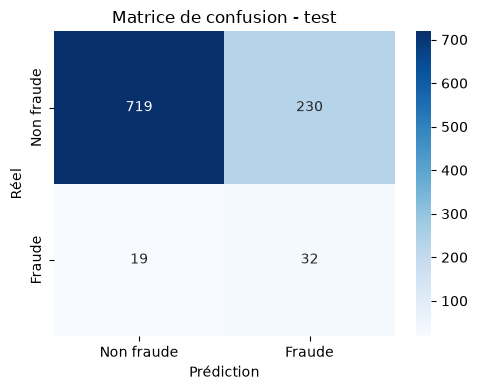

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import average_precision_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score

final_pred = best_pipeline.predict(X_test)
final_proba = best_pipeline.predict_proba(X_test)[:, 1]

precision = precision_score(y_test, final_pred, pos_label=1)
recall = recall_score(y_test, final_pred, pos_label=1)
f1 = f1_score(y_test, final_pred, pos_label=1)
ap = average_precision_score(y_test, final_proba)
cm = confusion_matrix(y_test, final_pred, labels=[0, 1])

print(f"Précision (classe 1) : {precision:.4f}")
print(f"Rappel (classe 1) : {recall:.4f}")
print(f"F1 (classe 1) : {f1:.4f}")
print(f"Average precision : {ap:.4f}")
print("\nRapport de classification :")
print(classification_report(y_test, final_pred, target_names=["Non fraude", "Fraude"], digits=4))
print("\nMatrice de confusion :")
print(cm)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Non fraude", "Fraude"], yticklabels=["Non fraude", "Fraude"])
plt.xlabel("Prédiction")
plt.ylabel("Réel")
plt.title("Matrice de confusion - test")
plt.tight_layout()
plt.show()


### (a) Pourquoi la précision globale n'est pas suffisante

Un modèle qui prédit presque toujours « non fraude » peut atteindre un très bon taux de précision globale, simplement parce que les fraudes sont rares. En fraude, ce qui compte surtout est la capacité à repérer les vrais cas positifs sans mettre trop de faux positifs.

### (b) Compromis entre faux positifs et faux négatifs

Un faux positif bloque un client légitime, ce qui entraîne du coût, de la friction et parfois de la frustration. Un faux négatif laisse passer une fraude réelle, ce qui peut coûter beaucoup plus cher à l'organisation et nuire à la confiance.

### (c) Effet d'un seuil plus bas

En abaissant le seuil de décision, on augmente le rappel et on détecte davantage de fraudes, mais on baisse aussi la précision. Le système devient plus agressif avec plus d'alertes, ce qui a un coût opérationnel plus élevé.

### (d) Pourquoi la validation temporelle est importante

Un split aléatoire mélange des transactions du passé et du futur, ce qui introduit des fuites et surestime les performances. En pratique, il faut entraîner sur le passé et tester sur le futur, car le comportement des fraudeurs et les schémas de fraude évoluent avec le temps.